In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os
from imblearn.over_sampling import RandomOverSampler
import warnings

warnings.filterwarnings("ignore")

Peeking the dataset

In [2]:
df = pd.read_csv(r"D:\projVehicleInsurance\vehicle-Insurance\notebooks\data.csv")
df.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


Lets do some EDA

In [3]:
df.shape

(381109, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  object 
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  object 
 7   Vehicle_Damage        381109 non-null  object 
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 34.9+ MB


In [5]:
df.describe()

,id,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Response
count,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000
mean,190555.000000,38.822584,0.997869,26.388807,0.458210,30564.389581,112.034295,154.347397,0.122563
std,110016.836208,15.511611,0.046110,13.229888,0.498251,17213.155057,54.203995,83.671304,0.327936
min,1.000000,20.000000,0.000000,0.000000,0.000000,2630.000000,1.000000,10.000000,0.000000
25%,95278.000000,25.000000,1.000000,15.000000,0.000000,24405.000000,29.000000,82.000000,0.000000
50%,190555.000000,36.000000,1.000000,28.000000,0.000000,31669.000000,133.000000,154.000000,0.000000
75%,285832.000000,49.000000,1.000000,35.000000,1.000000,39400.000000,152.000000,227.000000,0.000000
max,381109.000000,85.000000,1.000000,52.000000,1.000000,540165.000000,163.000000,299.000000,1.000000


In [6]:
df.isnull().sum()

id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64

In [7]:
value_counts = df["Response"].value_counts()

oooo highly imbalanced dataset it is

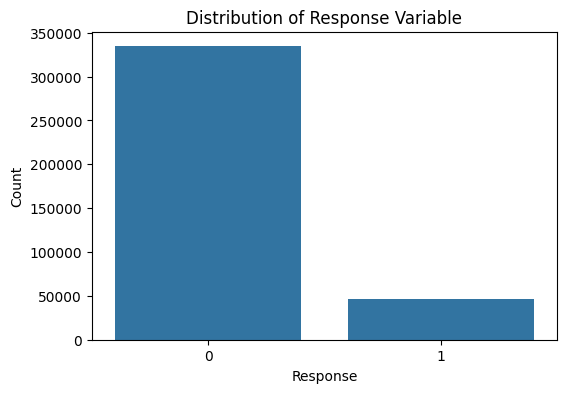

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Response", data=df)
plt.title("Distribution of Response Variable")
plt.xlabel("Response")
plt.ylabel("Count")
plt.show()


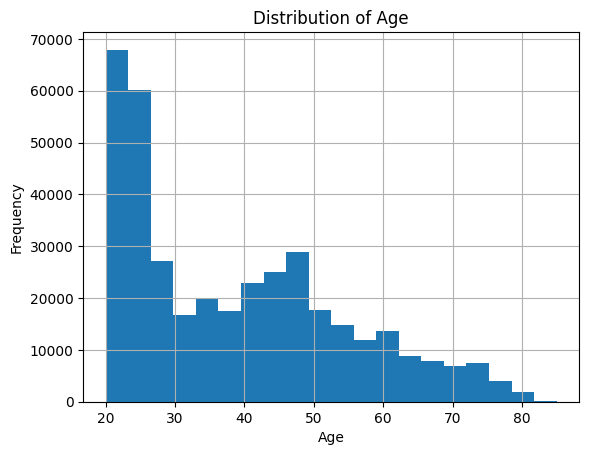

In [9]:
df["Age"].hist(bins=20)
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


lets analyse relation between age and annual premium to get idea of how users are distributed across age groups and how it affects their insurance premiums.

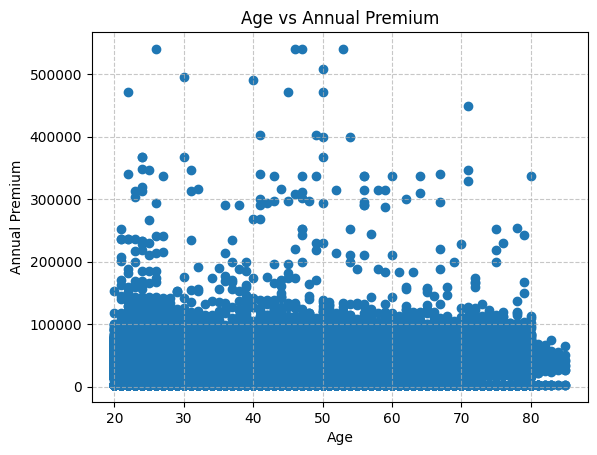

In [10]:
plt.scatter(df["Age"], df["Annual_Premium"])
plt.title("Age vs Annual Premium")
plt.xlabel("Age")
plt.ylabel("Annual Premium")
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()


now lets see relation between how gender is affecting the response variable.

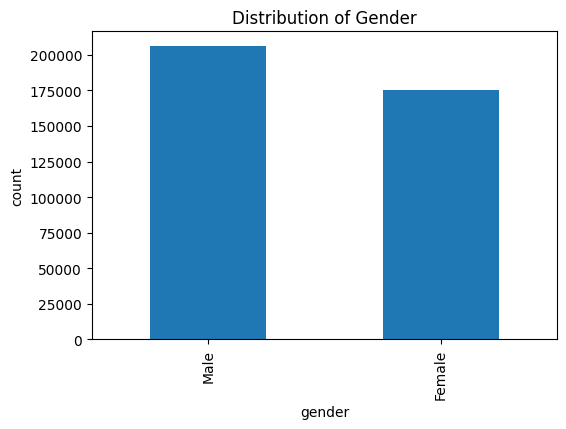

In [11]:
value = df["Gender"].value_counts()
plt.figure(figsize=(6, 4))
value.plot(kind="bar")
plt.xlabel("gender")
plt.ylabel("count")
plt.title("Distribution of Gender")
plt.show()

AttributeError: Line2D.set() got an unexpected keyword argument 'kinFd'

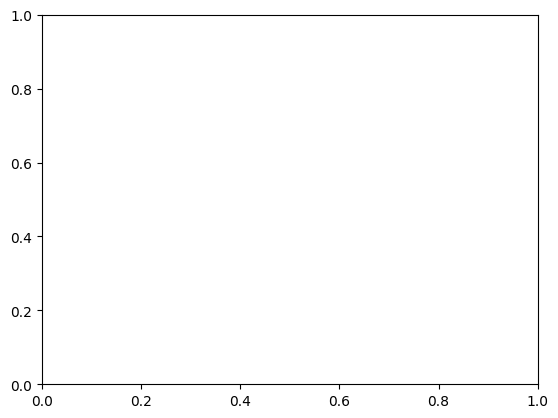

In [12]:
data = df.groupby(['Gender', 'Response']).size().unstack(fill_value=0)
data.plot(kinFd='bar', stacked=True)
plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Response Distribution by Gender')
plt.legend(title='Response', loc='upper right')
plt.show()

Now lets analyse gender vs driving license to see how many people have driving license

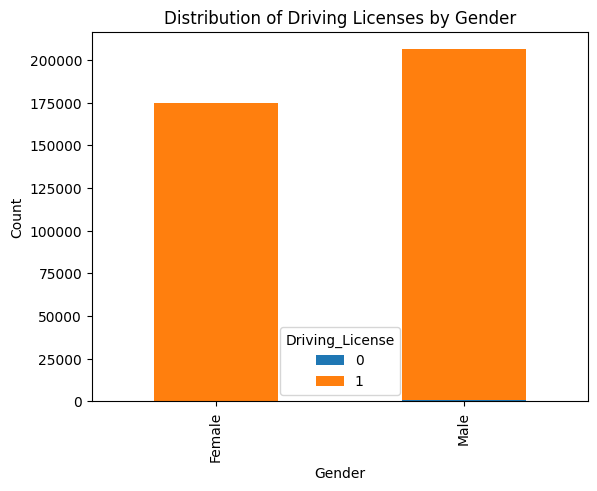

In [ ]:
data = df.groupby(["Gender"])["Driving_License"].value_counts().unstack(fill_value=0)
data.plot(kind="bar", stacked=True)
plt.xlabel("Gender")
plt.ylabel("Count")
plt.title("Distribution of Driving Licenses by Gender")
plt.show()

previously insured person 

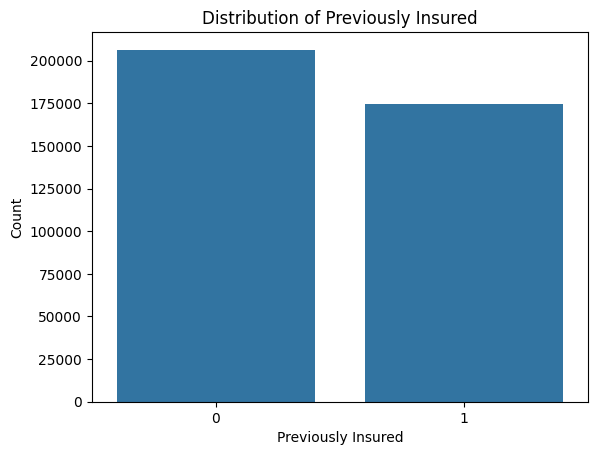

In [ ]:
sns.countplot(x="Previously_Insured", data=df)
plt.title("Distribution of Previously Insured")
plt.xlabel("Previously Insured")
plt.ylabel("Count")
plt.show()

vehicle age

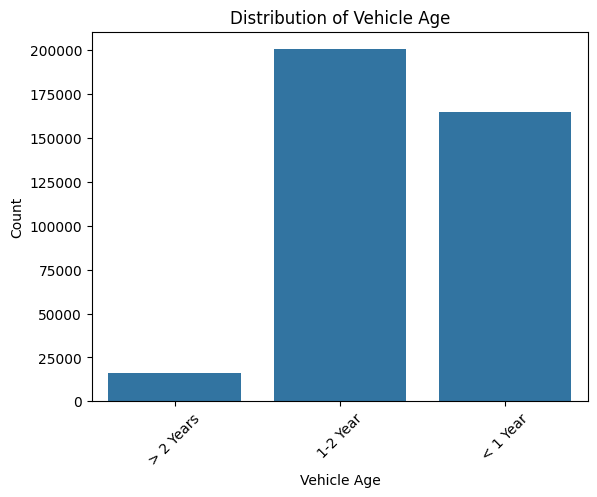

In [ ]:
sns.countplot(x="Vehicle_Age", data=df)
plt.xlabel("Vehicle Age")
plt.ylabel("Count")
plt.title("Distribution of Vehicle Age")
plt.xticks(rotation=45)
plt.show()

Response vs vehicle age

In [ ]:
data = (
    df.groupby(["Vehicle_Age", "Response"])["id"]
    .count()
    .to_frame()
    .rename(columns={"id": "count"})
    .reset_index()
)
data

,Vehicle_Age,Response,count
0,1-2 Year,0,165510
1,1-2 Year,1,34806
2,< 1 Year,0,157584
3,< 1 Year,1,7202
4,> 2 Years,0,11305
5,> 2 Years,1,4702


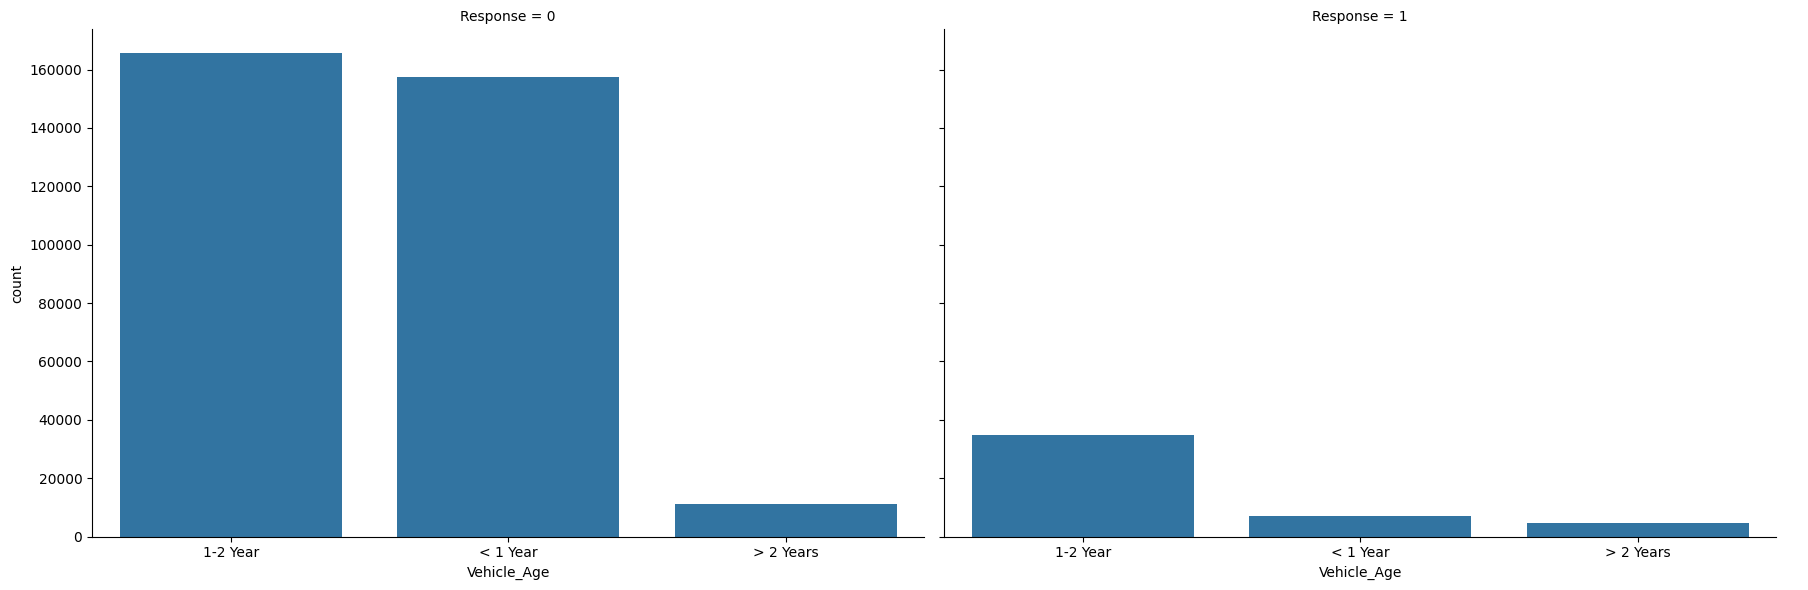

In [ ]:
sns.catplot(
    x="Vehicle_Age",
    y="count",
    col="Response",
    data=data,
    kind="bar",
    height=6,
    aspect=1.5,
)

lets see distribution for vehicle damage

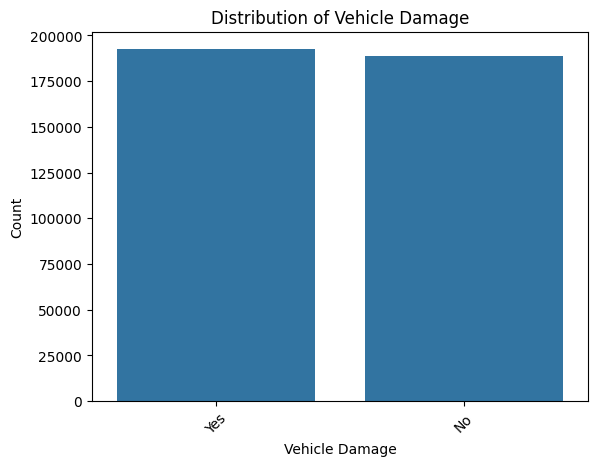

In [ ]:
sns.countplot(x="Vehicle_Damage", data=df)
plt.xlabel("Vehicle Damage")
plt.ylabel("Count")
plt.title("Distribution of Vehicle Damage")
plt.xticks(rotation=45)
plt.show()

In [ ]:
df["Annual_Premium"].describe()

count    381109.000000
mean      30564.389581
std       17213.155057
min        2630.000000
25%       24405.000000
50%       31669.000000
75%       39400.000000
max      540165.000000
Name: Annual_Premium, dtype: float64

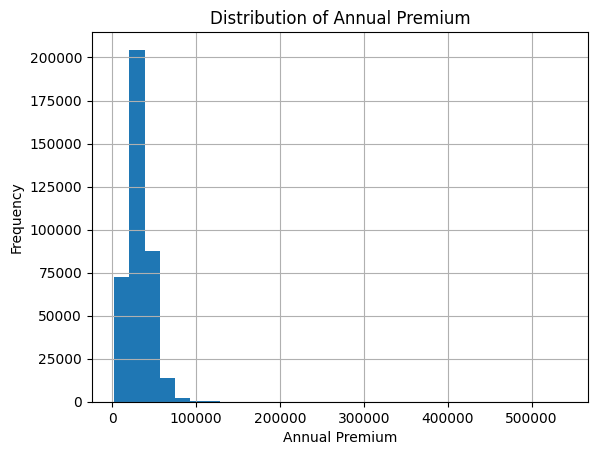

In [ ]:
df["Annual_Premium"].hist(bins=30)
plt.title("Distribution of Annual Premium")
plt.xlabel("Annual Premium")
plt.ylabel("Frequency")
plt.show()

### data preprocessing
enough of eda now lets do some data preprocessing before we move to modelling. We will do some feature engineering and then we will do some encoding of categorical variables and then we will do some scaling of numerical variables. After that we will split the data into train and test sets and then we will do some modelling.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  object 
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  object 
 7   Vehicle_Damage        381109 non-null  object 
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 34.9+ MB


In [15]:
X = df.drop(["id", "Response"], axis=1)
y = df["Response"]

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [17]:
X_train.head()

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage
332803,Female,39,1,15.0,0,1-2 Year,Yes,52906.0,55.0,227
116248,Male,38,1,11.0,0,1-2 Year,Yes,23038.0,26.0,29
255005,Male,22,1,30.0,1,< 1 Year,No,45318.0,152.0,166
317474,Female,23,1,41.0,1,< 1 Year,No,29132.0,151.0,277
344212,Male,56,1,48.0,0,> 2 Years,Yes,2630.0,154.0,155


In [18]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

In [19]:
X_train.head()

,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Gender_Male,Vehicle_Age_< 1 Year,Vehicle_Age_> 2 Years,Vehicle_Damage_Yes
332803,39,1,15.0,0,52906.0,55.0,227,False,False,False,True
116248,38,1,11.0,0,23038.0,26.0,29,True,False,False,True
255005,22,1,30.0,1,45318.0,152.0,166,True,True,False,False
317474,23,1,41.0,1,29132.0,151.0,277,False,True,False,False
344212,56,1,48.0,0,2630.0,154.0,155,True,False,True,True


In [20]:
# both train and test have same columns after one hot encoding
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

In [21]:
X_train.columns = (
    X_train.columns.str.replace("<", "lessthan", regex=False)
    .str.replace(">", "greaterthan", regex=False)
    .str.replace(" ", "_", regex=False)
)
X_test.columns = (
    X_test.columns.str.replace("<", "lessthan", regex=False)
    .str.replace(">", "greaterthan", regex=False)
    .str.replace(" ", "_", regex=False)
)

In [22]:
X_train.head()

,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Gender_Male,Vehicle_Age_lessthan_1_Year,Vehicle_Age_greaterthan_2_Years,Vehicle_Damage_Yes
332803,39,1,15.0,0,52906.0,55.0,227,False,False,False,True
116248,38,1,11.0,0,23038.0,26.0,29,True,False,False,True
255005,22,1,30.0,1,45318.0,152.0,166,True,True,False,False
317474,23,1,41.0,1,29132.0,151.0,277,False,True,False,False
344212,56,1,48.0,0,2630.0,154.0,155,True,False,True,True


In [23]:
num_cols = ["Age", "Annual_Premium", "Vintage"]

In [24]:
scaler = StandardScaler()

In [25]:
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [26]:
X_train.head()

,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Gender_Male,Vehicle_Age_lessthan_1_Year,Vehicle_Age_greaterthan_2_Years,Vehicle_Damage_Yes
332803,0.010601,1,15.0,0,1.294417,55.0,0.869505,False,False,False,True
116248,-0.053875,1,11.0,0,-0.436638,26.0,-1.497719,True,False,False,True
255005,-1.085502,1,30.0,1,0.854640,152.0,0.140209,True,True,False,False
317474,-1.021025,1,41.0,1,-0.083449,151.0,1.467289,False,True,False,False
344212,1.106704,1,48.0,0,-1.619422,154.0,0.008696,True,False,True,True


In [27]:
import mlflow
import mlflow.sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV


In [29]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Vehicle Insurance Prediction(Imbalanced Data)")
mlflow.sklearn.autolog(disable=False)

2026/03/25 23:37:07 INFO mlflow.tracking.fluent: Experiment with name 'Vehicle Insurance Prediction(Imbalanced Data)' does not exist. Creating a new experiment.


In [30]:
experiments = {
    "logistic_regression": (
        LogisticRegression(max_iter=1000, random_state=42),
        {"C": [0.01, 0.1, 1, 10, 100], "class_weight": [None, "balanced"]},
    ),
    "Random_Forest": (
        RandomForestClassifier(random_state=42),
        {
            "n_estimators": [100, 200, 300],
            "max_depth": [None, 5, 10, 15],
            "min_samples_split": [2, 5, 10],
            "class_weight": [None, "balanced"],
        },
    ),
    "LightGBM": (
        lgb.LGBMClassifier(random_state=42, n_jobs=-1),
        {
            "learning_rate": [0.01, 0.05, 0.1],
            "n_estimators": [100, 200, 300],
            "max_depth": [3, 5, 7],
            "class_weight": [None, "balanced"],
        },
    ),
}

In [31]:
for model_name, (clf, param_grid) in experiments.items():
    print(f"\n--- Starting Experiment for: {model_name} ---")
    with mlflow.start_run(run_name=f"{model_name}_RandomSearch_Imbalanced"):
        search = RandomizedSearchCV(
            estimator=clf,
            param_distributions=param_grid,
            n_iter=5,
            cv=3,
            scoring="roc_auc",
            random_state=42,
            n_jobs=-1,
        )
        search.fit(X_train, y_train)

        best_model = search.best_estimator_
        y_pred = best_model.predict(X_test)
        y_proba = best_model.predict_proba(X_test)[:, 1]

        test_accuracy = accuracy_score(y_test, y_pred)
        test_precision = precision_score(y_test, y_pred)
        test_recall = recall_score(y_test, y_pred)
        test_f1 = f1_score(y_test, y_pred)
        test_roc_auc = roc_auc_score(y_test, y_proba)

        mlflow.log_metric("test_accuracy", test_accuracy)
        mlflow.log_metric("test_precision", test_precision)
        mlflow.log_metric("test_recall", test_recall)
        mlflow.log_metric("test_f1_score", test_f1)
        mlflow.log_metric("test_roc_auc", test_roc_auc)

        print(f"Best Parameters for {model_name}: {search.best_params_}")
        print(f"Test Accuracy: {test_accuracy:.4f}")
        print(f"Test Precision: {test_precision:.4f}")
        print(f"Test Recall: {test_recall:.4f}")
        print(f"Test F1 Score: {test_f1:.4f}")
        print(f"Test ROC AUC: {test_roc_auc:.4f}")

        print(f"--- Completed Experiment for: {model_name} ---\n")



--- Starting Experiment for: logistic_regression ---


2026/03/25 23:41:33 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/25 23:42:07 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/03/25 23:42:23 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/25 23:42:38 W

🏃 View run learned-robin-949 at: http://127.0.0.1:5000/#/experiments/1/runs/08c1a30a87f0460fb48798d5378f4f45
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run placid-stag-30 at: http://127.0.0.1:5000/#/experiments/1/runs/07f610994b934bfea703ab1b41872219
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run bedecked-tern-145 at: http://127.0.0.1:5000/#/experiments/1/runs/b4c0ee7f38a44d0388ae8fe0854e4109
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run burly-crane-568 at: http://127.0.0.1:5000/#/experiments/1/runs/9710a3cc62594e98b6e1befaa1115553
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run worried-steed-708 at: http://127.0.0.1:5000/#/experiments/1/runs/bd40535c6f2c4ffc9143e708ecc98371
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Best Parameters for logistic_regression: {'class_weight': None, 'C': 100}
Test Accuracy: 0.8751
Test Precision: 1.0000
Test Recall: 0.0001
Test F1 Score: 0.0002

2026/03/25 23:53:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/25 23:53:43 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/03/25 23:55:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/25 23:55:15 W

🏃 View run overjoyed-wren-322 at: http://127.0.0.1:5000/#/experiments/1/runs/6706af3d50644c38878d924134591744
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run overjoyed-mole-264 at: http://127.0.0.1:5000/#/experiments/1/runs/fe2116d5a6ad4f6ea01055d02adb48a9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run stately-bird-491 at: http://127.0.0.1:5000/#/experiments/1/runs/bf5a36409c554b939a02b3feb37bd3d7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run awesome-horse-485 at: http://127.0.0.1:5000/#/experiments/1/runs/efc8e0d51ece45538ec04e0c22fe1ab9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run nimble-doe-830 at: http://127.0.0.1:5000/#/experiments/1/runs/f68e52803ca64c79a7ab3a297ed4ff45
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Best Parameters for Random_Forest: {'n_estimators': 200, 'min_samples_split': 2, 'max_depth': 15, 'class_weight': None}
Test Accuracy: 0.8753
Test Precision:

2026/03/25 23:57:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/25 23:57:15 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/03/25 23:57:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/25 23:57:31 W

🏃 View run unruly-hog-478 at: http://127.0.0.1:5000/#/experiments/1/runs/d45b08394ec04ca1997427052b0fe220
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run overjoyed-chimp-414 at: http://127.0.0.1:5000/#/experiments/1/runs/745c7fdc154d42dbad1959e390ee093a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run worried-stork-60 at: http://127.0.0.1:5000/#/experiments/1/runs/ed659ded27174912861bef5f215d2a41
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run wise-horse-854 at: http://127.0.0.1:5000/#/experiments/1/runs/d66fd624491d48d3991fa18276539810
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run vaunted-sow-234 at: http://127.0.0.1:5000/#/experiments/1/runs/edf0e596887f4b96be8b091a03931297
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Best Parameters for LightGBM: {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1, 'class_weight': None}
Test Accuracy: 0.8751
Test Precision: 0.5476
Test 